<a href="https://colab.research.google.com/github/Fathina-codes/FDS_Record/blob/main/Ex_2_ipynp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

         Date     Product  Quantity  Sales Region
0  2024-01-01      Laptop         2   2000  North
1  2024-01-02  Smartphone         5   3500  South
2  2024-01-03      Tablet         3   1800   East
3  2024-01-04  Headphones        10   1500   West
4  2024-01-05  Smartwatch         4   2000  North
Date        0
Product     0
Quantity    0
Sales       0
Region      0
dtype: int64
        Quantity       Sales
count  50.000000    50.00000
mean    4.520000  1542.00000
std     3.265403  1000.42644
min     1.000000   400.00000
25%     2.000000   800.00000
50%     4.000000  1200.00000
75%     6.000000  2000.00000
max    15.000000  4500.00000
      Product  Sales  Quantity
0      Camera  13500         9
1  Headphones   5400        36
2    Keyboard   3600        36
3      Laptop   9000         9
4     Monitor   6000        15
5       Mouse   2800        56
6     Printer   4800        12
7  Smartphone  14000        20
8  Smartwatch   9000        18
9      Tablet   9000        15


/tmp/ipykernel_810/384773573.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sales'].fillna(df['Sales'].mean(), inplace=True)


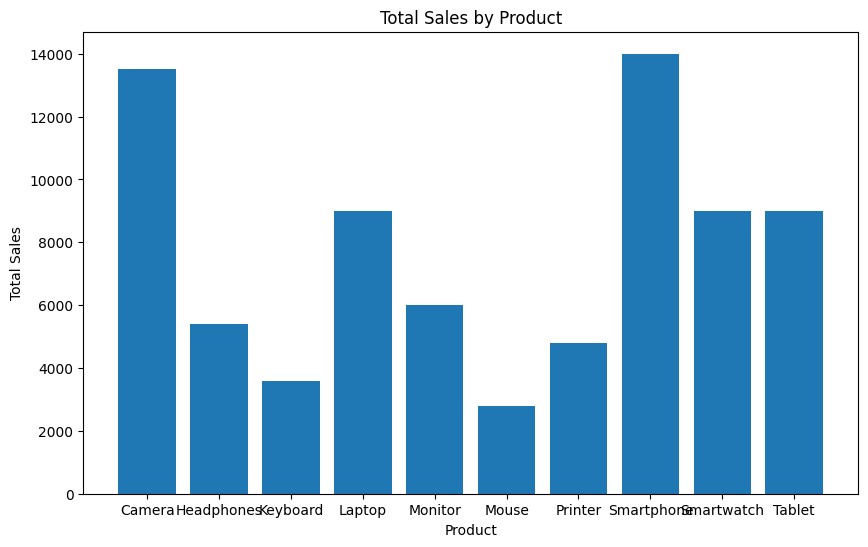

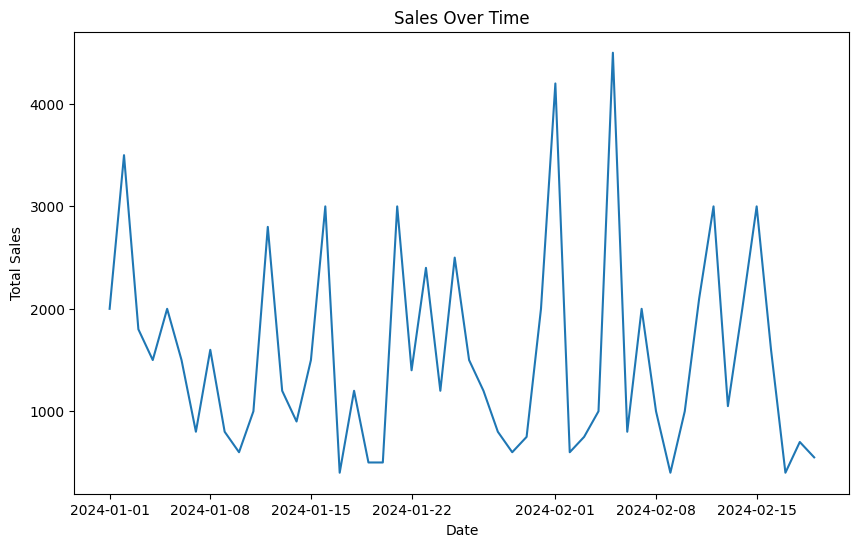

/tmp/ipykernel_810/384773573.py:40: FutureWarning: The provided callable <function sum at 0x7efff17353a0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pivot_table = df.pivot_table(


Product  Camera  Headphones  Keyboard  Laptop  Monitor  Mouse  Printer  \
Region                                                                   
East          0           0      1500    3000        0      0     3600   
North         0           0      2100    6000        0      0     1200   
South      6000        1650         0       0     3200   1900        0   
West       7500        3750         0       0     2800    900        0   

Product  Smartphone  Smartwatch  Tablet  
Region                                   
East              0        2500    7200  
North             0        6500    1800  
South          7000           0       0  
West           7000           0       0  
          Quantity     Sales
Quantity  1.000000 -0.207355
Sales    -0.207355  1.000000


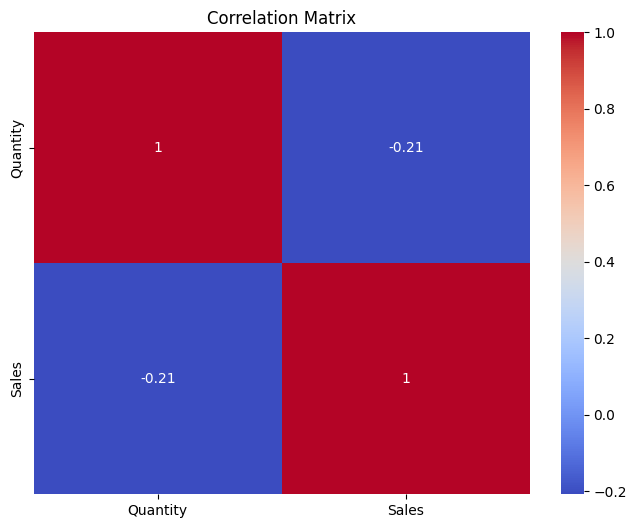

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/sales_data.csv'
df = pd.read_csv(file_path)

print(df.head())
print(df.isnull().sum())

df['Sales'].fillna(df['Sales'].mean(), inplace=True)
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

print(df.describe())

product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()
print(product_summary)

plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.show()

pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc=np.sum,
    fill_value=0
)
print(pivot_table)

correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()